In [4]:
# Taken from a tutorial: https://www.datacamp.com/community/tutorials/wordcloud-python

import numpy as np
import pandas as pd
from os import path
# from PIL import Image
from wordcloud import WordCloud, STOPWORDS, ImageColorGenerator
import matplotlib.pyplot as plt
% matplotlib inline

In [2]:
import bibtexparser

In [3]:
with open('foo.txt') as fil:
    lines = fil.read()

database = bibtexparser.loads(lines)

In [4]:
print('There are {} entries in this database'.format(len(database.entries_dict)))

There are 93 entries in this database


In [5]:
df = pd.DataFrame.from_dict(database.entries_dict)
df.head()

,Nord,Schichl,Šilar,Ritter,Reichl,Abel,Grether,Thomas,Aoyama,Härdin,...,Stüber,Samlaus,Menager,Henningsson,Desmet,Pitchaikani,Sohn,Paepcke,Pipiorke,Meyer
ENTRYTYPE,inproceedings,inproceedings,inproceedings,inproceedings,inproceedings,inproceedings,inproceedings,inproceedings,inproceedings,inproceedings,...,inproceedings,inproceedings,inproceedings,inproceedings,inproceedings,inproceedings,inproceedings,inproceedings,inproceedings,inproceedings
ID,Nord,Schichl,Šilar,Ritter,Reichl,Abel,Grether,Thomas,Aoyama,Härdin,...,Stüber,Samlaus,Menager,Henningsson,Desmet,Pitchaikani,Sohn,Paepcke,Pipiorke,Meyer
abstract,Dynamic process models of the capture unit of ...,State-of-the-art Modelica implementations may ...,The integrative model of human physiology conn...,"During aircraft design and certification, one ...",Transient thermodynamic models in Modelica are...,This paper presents a concept for online param...,High crosswinds affect the stability of railwa...,Floating offshore wind turbines are getting mo...,This paper describes a method for early stage ...,We present a software infrastructure to perfor...,...,A variable-structure model (VSM) of a battery ...,"Connected, Automated, Electrified. These three...",In order to stay competitive the requirements ...,FMI is increasingly being adopted as a standar...,This paper presents an application case for th...,This paper describes a model-driven approach t...,Multizone models are widely used in building a...,We discuss the application of the FMI Co-Simul...,Building physics and HVAC system simulation ha...,The application of the FMI technology gains gr...
author,"Montañés, Rubén M. and Nord, Lars Olof","Baharev, Ali and Neumaier, Arnold and Schichl,...","Kofránek, Jirí and Kulhánek, Tomáš and Mateják...","Müller, Reiko and Ritter, Markus","Emhofer, Johann and Zitzenbacher, Raimund and ...","Gesenhues, Jonas and Hein, Marc and Ketelhut, ...","Heckmann, Andreas and Grether, Gustav","Leimeister, Mareike and Thomas, Philipp","Trentelman, Thom and Sutherland, Joshua and Oi...","Lacoursière, Claude and Härdin, Tomas",...,"Stüber, Moritz","Mikelsons, Lars and Samlaus, Roland","Kampfmann, Rüdiger and Mösch, Danny and Menage...","Durling, Erik and Palmkvist, Elias and Henning...","Gonzalez Cocho, Mikel and Salgado, Oscar and C...","Magargle, Ryan and Johnson, Lee and Mandloi, P...","Tian, Wei and Zuo, Wangda and Sevilla, Thomas ...","Nicolai, Andreas and Paepcke, Anne","Schwan, Torsten and Unger, René and Pipiorke, ...","Clauß, Christoph and Majetta, Kristin and Meye..."
booktitle,Proceedings of the 12th International Modelica...,Proceedings of the 12th International Modelica...,Proceedings of the 12th International Modelica...,Proceedings of the 12th International Modelica...,Proceedings of the 12th International Modelica...,Proceedings of the 12th International Modelica...,Proceedings of the 12th International Modelica...,Proceedings of the 12th International Modelica...,Proceedings of the 12th International Modelica...,Proceedings of the 12th International Modelica...,...,Proceedings of the 12th International Modelica...,Proceedings of the 12th International Modelica...,Proceedings of the 12th International Modelica...,Proceedings of the 12th International Modelica...,Proceedings of the 12th International Modelica...,Proceedings of the 12th International Modelica...,Proceedings of the 12th International Modelica...,Proceedings of the 12th International Modelica...,Proceedings of the 12th International Modelica...,Proceedings of the 12th International Modelica...


In [10]:
# Test on a single abstract

text = df.get_value('abstract', 'Nord')
print ("There are {} words in this single abstract.".format(len(text)))

There are 894 words in this single abstract.


/home/vmg/anaconda3/lib/python3.6/site-packages/ipykernel_launcher.py:3: FutureWarning: get_value is deprecated and will be removed in a future release. Please use .at[] or .iat[] accessors instead
  This is separate from the ipykernel package so we can avoid doing imports until


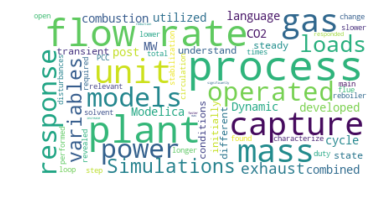

In [11]:
# Generate a word cloud image
wordcloud = WordCloud(max_font_size=50, max_words=100, background_color="white").generate(text)

# Display the generated image:
plt.figure()
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis("off")
plt.show()
wordcloud.to_file("first_review.png")

In [12]:
# Now get all abstracts and combine
text = " ".join(df.get_value('abstract', col) for col in df.columns)
print ("There are {} words in the combination of all abstracts.".format(len(text)))

There are 84083 words in the combination of all abstracts.


/home/vmg/anaconda3/lib/python3.6/site-packages/ipykernel_launcher.py:2: FutureWarning: get_value is deprecated and will be removed in a future release. Please use .at[] or .iat[] accessors instead
  


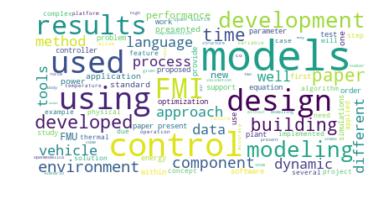

In [22]:
# Create stopword list:
stopwords = set(STOPWORDS)
stopwords.update(['simulation', 'Modelica', 'model', 'system','systems', 'based','result','tool','package','library',])

# Generate a word cloud image
wordcloud = WordCloud(max_font_size=50, max_words=100, stopwords=stopwords, background_color="white").generate(text)

# Display the generated image:
plt.figure()
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis("off")
plt.show()
wordcloud.to_file("first_review.png")

In [104]:
# Create word cloud from entire proceedings

import os

DIR = 'InternationalModelicaConference/textcleaned'

text_full = ''
text_full_list = {}
for name in os.listdir(DIR):
    if os.path.isfile(os.path.join(DIR, name)):
        with open(os.path.join(DIR, name),'r') as fil:
            temp = fil.read().lower()
        text_full_list[name.replace('.txt','')] = temp
        text_full += ' ' + temp.replace('-\\n')
print ("There are {} words in all files.".format(len(text_full)))

There are 29371240 words in all files.


In [105]:
# Remove all single letter words
text_full = ' '.join( [w for w in text_full.split() if len(w)>1] )

# Remove trailing 's' on words (i.e., words => word)
# text_full = ' '.join(w[:-1] if w[-1]== 's' else w for w in text_full.split() )

In [106]:
print ("There are {} words in all files.".format(len(text_full)))

There are 28424170 words in all files.


In [142]:
# Create stopword list:
stopwords = set(STOPWORDS)

months = ['january','february','march','april','may','june','july','august','september','october','november','december']
locations = ['italy','germany','france','czech','republic','munich','lund','sweden']
numbers = ['1st','2nd','3rd','4th','5th','6th','7th','8th','9th','10th','11th','12th','13th','14th','15th','16th',
           '17th','18th','19th','20th','21st','22nd','23rd','24th','25th','26th','27th','28th','29th','20th','31st',
           'first','second','third','fourth','fifth','sixth','seventh','eighth','ninth','tenth']
modelica = ['equation','function','type','parameter','component','example','contain','within','real','boolean',
            'string','package','modelica']

stopwords_add = months+locations+numbers+modelica+[
                'proceeding','simulation', 'model', 'system','based','result','tool',
                'library','used','developed','using','approach','present','use',
                'paper','well','one','thu','figure','will','et al','international conference','international',
                'conference','conference september','DOI','two','association','thus','within','et','al']
    
# Additional stopwords based on lists
# - and 's' to end of each word for plurals
# - capitalize each word (REMOVED as added to read step):  + [word.capwords() for word in stopwords_add]
stopwords_add = stopwords_add + [word+'s' for word in stopwords_add]

# Update stopwords
stopwords.update(stopwords_add)

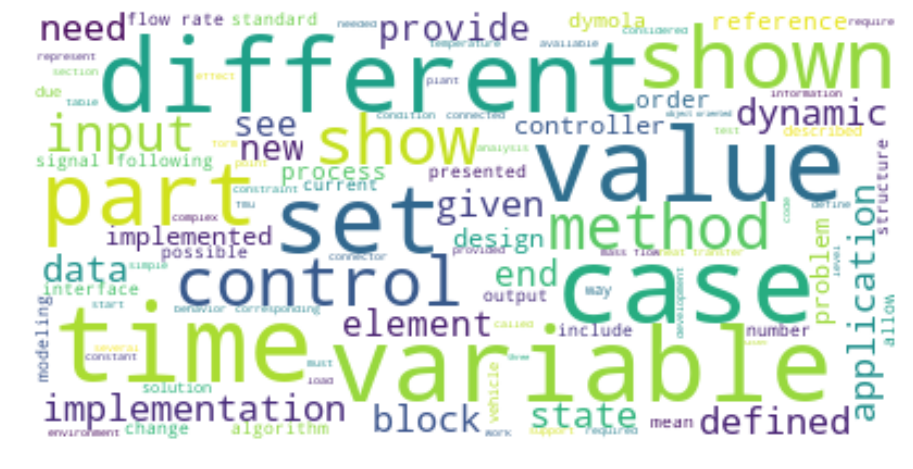

In [109]:
# For entire text

# Generate a word cloud image
wordcloud = WordCloud(max_font_size=50, max_words=100, stopwords=stopwords, background_color="white").generate(text_full)

# Display the generated image:
plt.figure(figsize=(16,8))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis("off")
plt.show()

s = os.path.split(DIR)[:-1]
figName = os.path.join(*s,'plots','text_full')

wordcloud.to_file('{}.png'.format(figName))

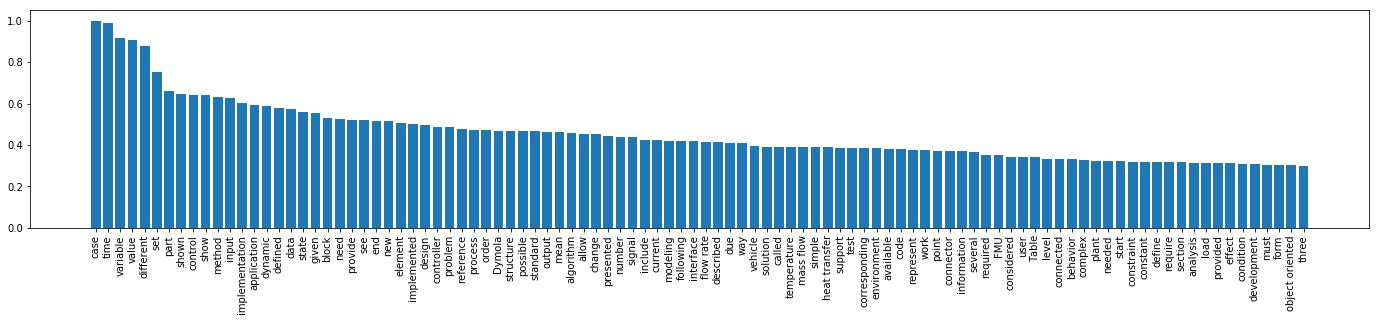

In [99]:
# Bar plot for visualing most common
fig = plt.figure(figsize=(24,4))
plt.bar(wordcloud.words_.keys(),wordcloud.words_.values())
plt.xticks(rotation='vertical');

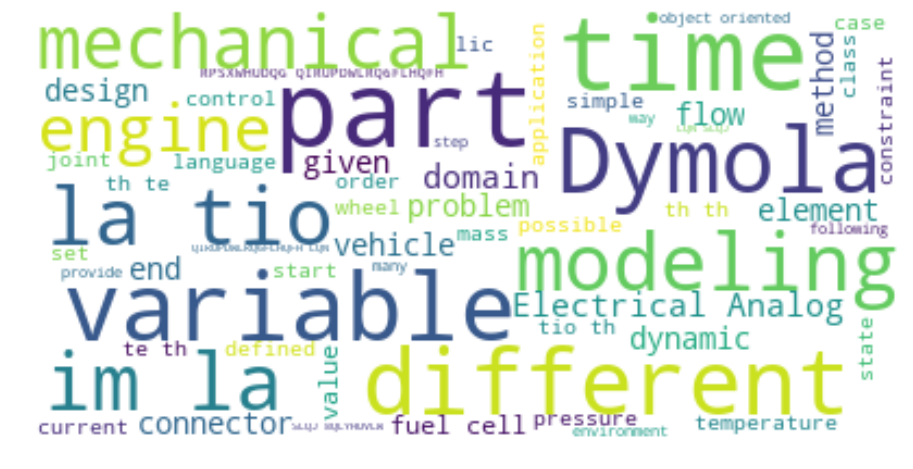

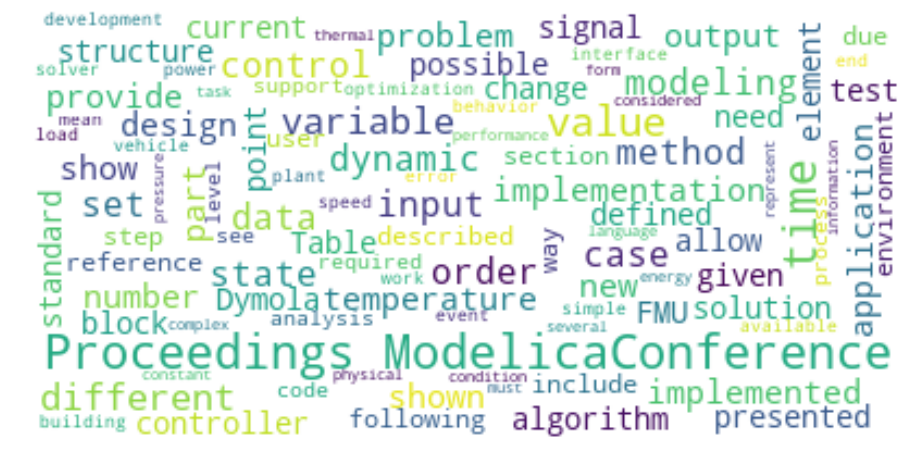

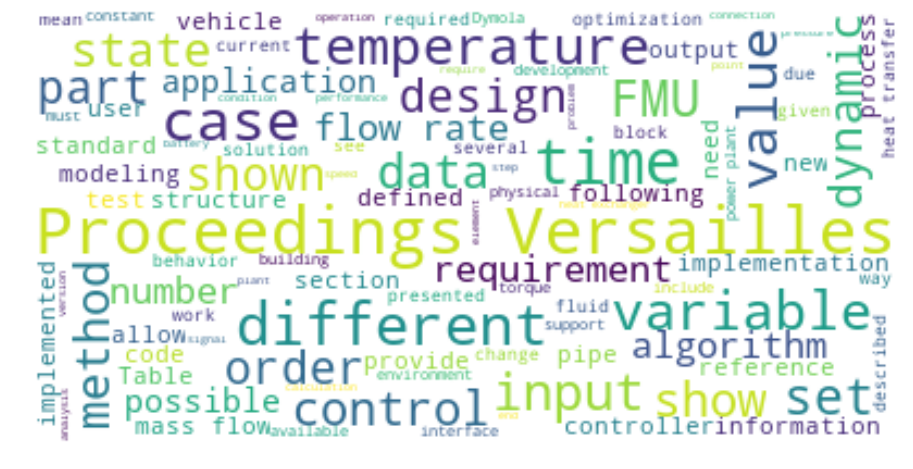

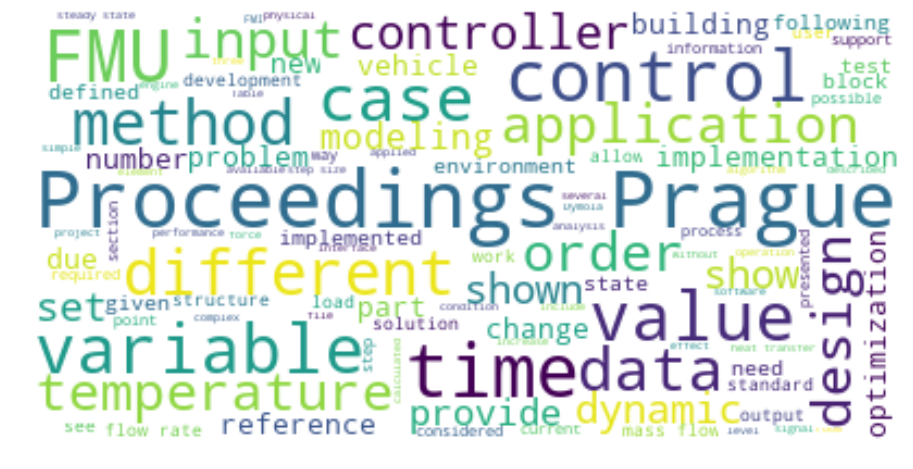

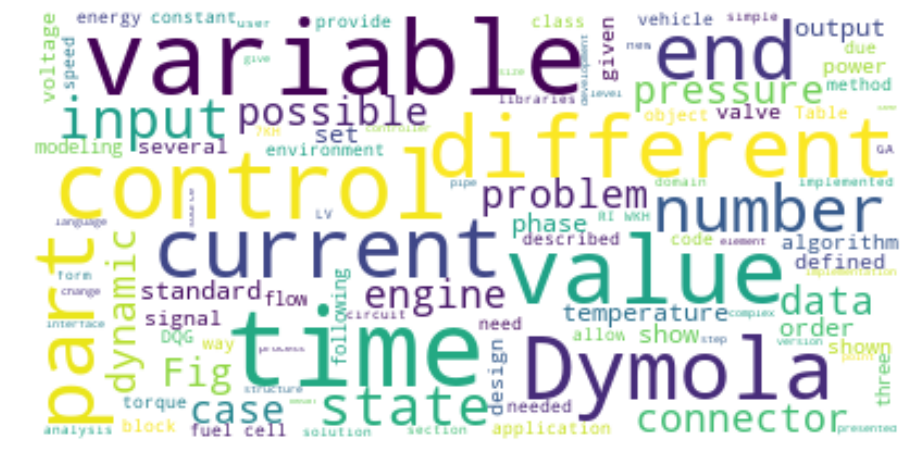

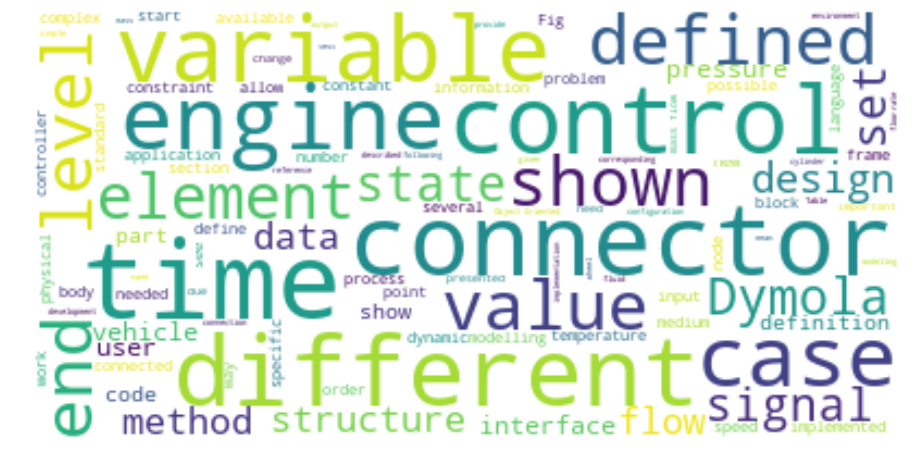

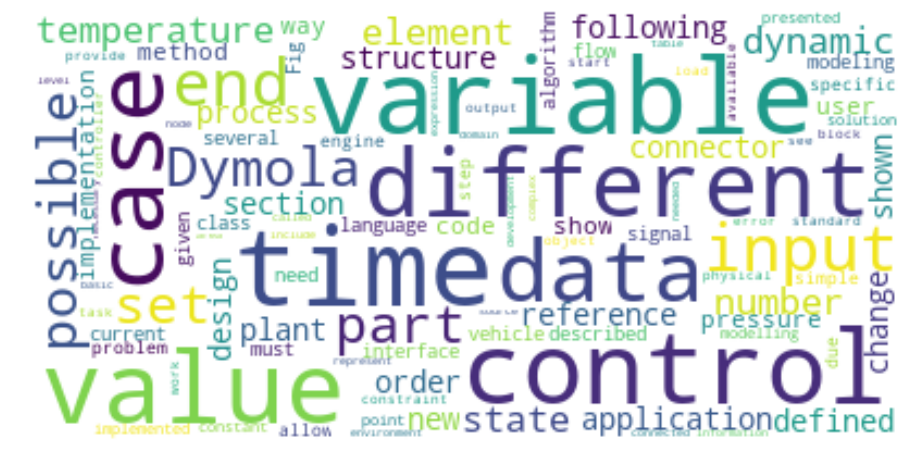

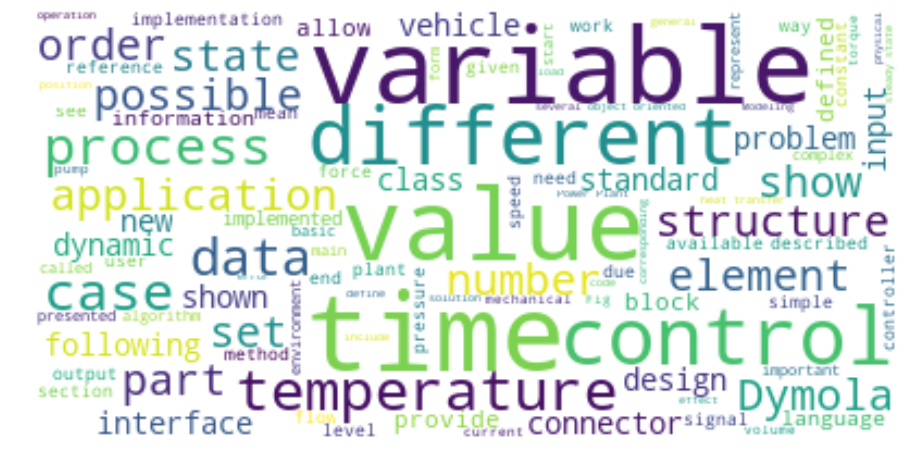

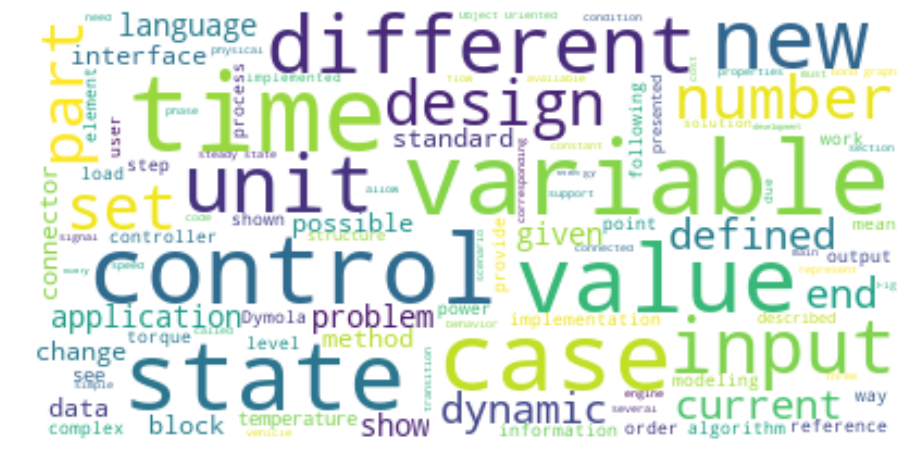

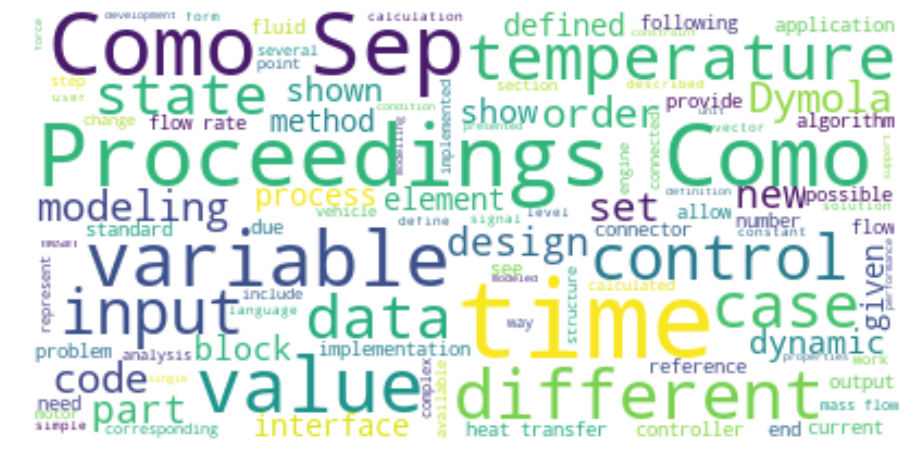

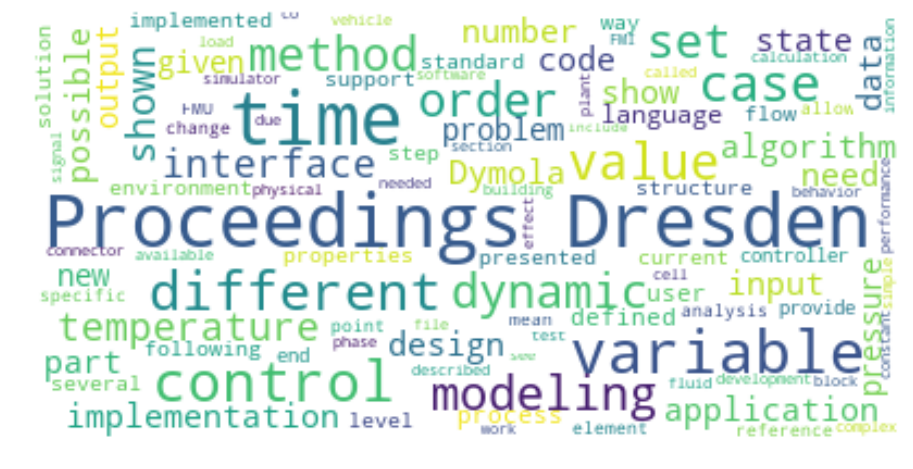

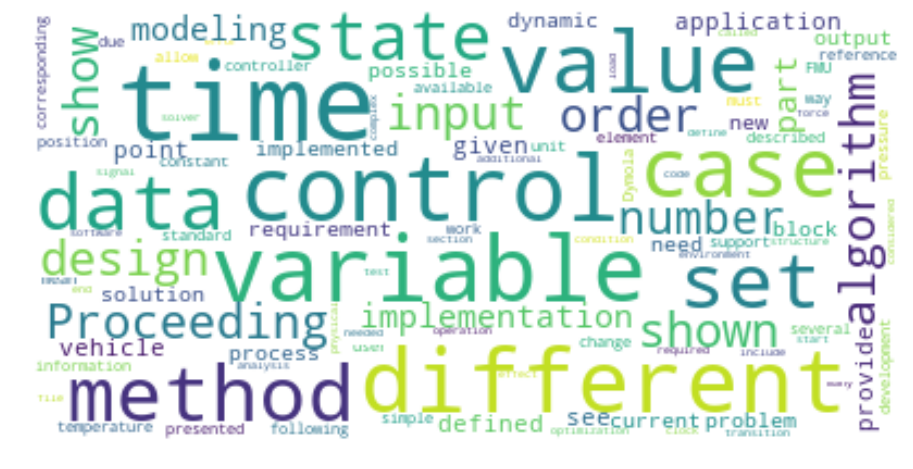

In [100]:
# Per conference text

for key, val in text_full_list.items():
    
    val = ' '.join( [w for w in val.split() if len(w)>1] )
    
    # Generate a word cloud image
    wordcloud = WordCloud(max_font_size=50, max_words=100, stopwords=stopwords, background_color="white").generate(val)

    # Display the generated image:
    plt.figure(figsize=(16,8))
    plt.imshow(wordcloud, interpolation='bilinear')
    plt.axis("off")

    s = os.path.split(DIR)[:-1]
    figName = os.path.join(*s,'plots',key)

    wordcloud.to_file('{}.png'.format(figName))

In [118]:
# Set keywords to be counted
includeWords = ['thermal','hydraulic','fluid','heat','transfer']

In [120]:
# Count number of each of the includeWords
includeWordsCount = dict.fromkeys(includeWords)
for word in includeWords:
    includeWordsCount[word] = text_full.split().count(word)

In [140]:
# # Create list and then string of repeated values to regenerate input for wordCloud
# text_includeWords_list = [key for key, value in includeWordsCount.items() for i in range(value)]
# text_includeWords = ' '.join(text_includeWords_list)

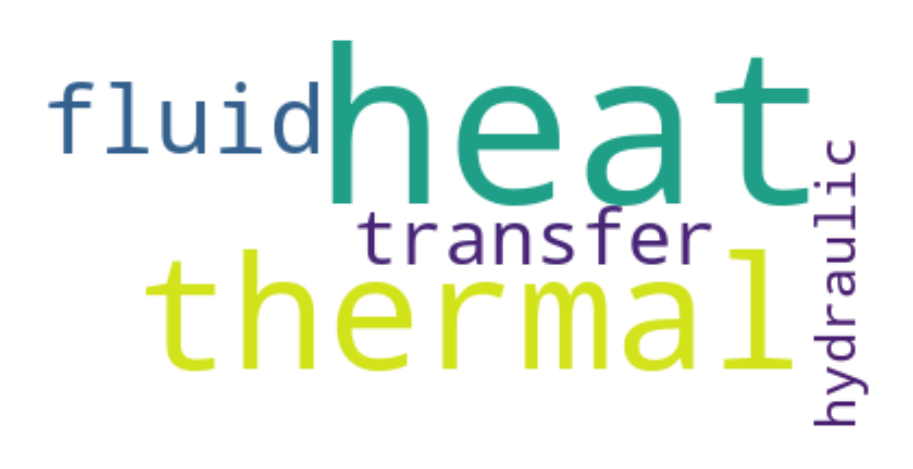

In [154]:
# For entire text

# Generate a word cloud image
wordcloud = WordCloud(background_color="white").generate_from_frequencies(includeWordsCount)

# Display the generated image:
plt.figure(figsize=(16,8))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis("off")
plt.show()

s = os.path.split(DIR)[:-1]
figName = os.path.join(*s,'plots','text_includeWords')

wordcloud.to_file('{}.png'.format(figName))